In [1]:
import pandas as pd 

In [2]:
#TASK 23: Missing values audit
# loading the csv file int o the dataframe
df = pd.read_csv("dirty/dirty_cafe_sales.csv")
df

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11
...,...,...,...,...,...,...,...,...
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02


In [3]:
#checking shape of dataframe
df.shape

(10000, 8)

In [4]:
#i, Finding the missing value count per column
df.isnull().sum()

Transaction ID         0
Item                 333
Quantity             138
Price Per Unit       179
Total Spent          173
Payment Method      2579
Location            3265
Transaction Date     159
dtype: int64

In [5]:
#ii, Finding the percentage of missing values per column
percentage_missing_values = df.isnull().mean()*100
percentage_missing_values

Transaction ID       0.00
Item                 3.33
Quantity             1.38
Price Per Unit       1.79
Total Spent          1.73
Payment Method      25.79
Location            32.65
Transaction Date     1.59
dtype: float64

In [6]:
# Combining the results of i and ii on a table(a new dataframe)to form the missing audit
missing_report = pd.DataFrame({"Missing count":df.isnull().sum(),"Missing_Percentage":df.isnull().mean()*100})

missing_report

,Missing count,Missing_Percentage
Transaction ID,0,0.00
Item,333,3.33
Quantity,138,1.38
Price Per Unit,179,1.79
Total Spent,173,1.73
Payment Method,2579,25.79
Location,3265,32.65
Transaction Date,159,1.59


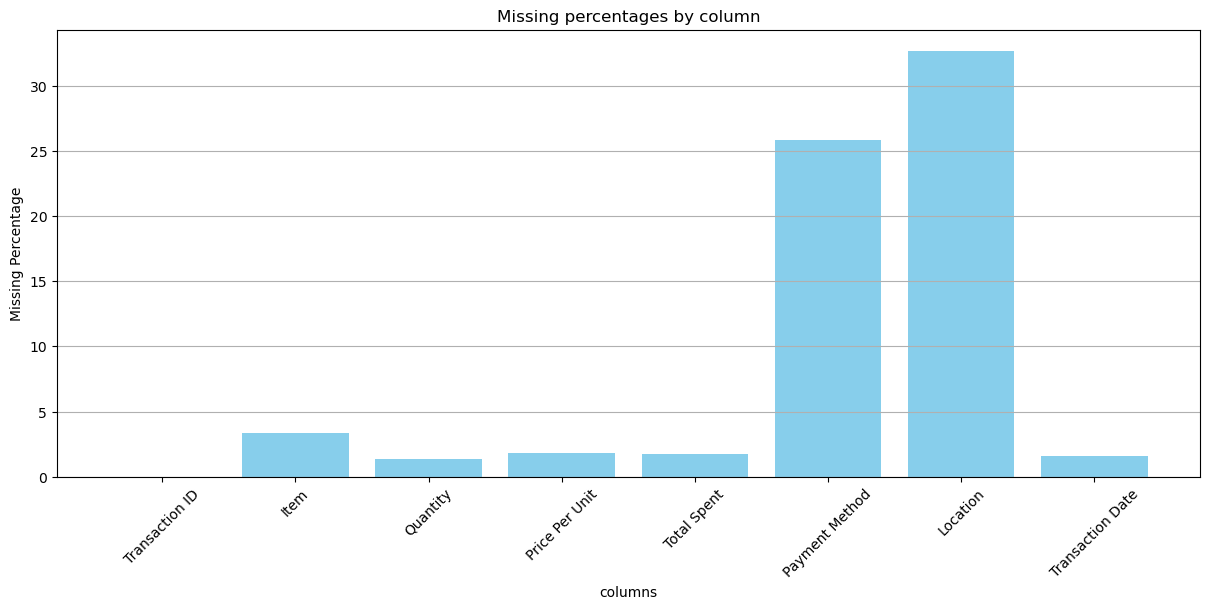

In [7]:
#iii, Visualizing the missing percentages per column using a bar chart

import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.bar(percentage_missing_values.index,
        percentage_missing_values.values, 
        color = "skyblue"
        )

#costumizations 
plt.xticks(rotation=45)
plt.grid(axis = "y")
plt.title("Missing percentages by column")
plt.tight_layout()
plt.ylabel("Missing Percentage")
plt.xlabel("columns")
plt.show()

# cleanning plan
Columns with a small percentage of missing values will be filled using an appropriate method. Numerical columns may use the median, while categorical columns may use the mode. Columns with an extremely high percentage of missing values may be removed if they do not provide enough useful information.

In [8]:
#TASK 24: IMPUTATION STUDY: applying imputation study(mean, median and mode) on a numerical(quantity) column

In [9]:
#The data was so messy such that the Quantity column had some values which are not numerical so we have to convert them to numerical values 
df["Quantity"]=pd.to_numeric(df["Quantity"],errors="coerce") 

In [10]:
# we will be creating 3 copies of the original dataframe(df) to work with because we do not want to mess up the original data frame(df)
Mean_df = df.copy()
Median_df = df.copy()
Mode_df = df.copy()

In [11]:
# checking the missing values for the quantity column
df["Quantity"].isnull().sum()

np.int64(479)

In [12]:
# Calculating the mean,median and mode of the Quantity column and handling the missing values
mean_value = df["Quantity"].mean()
mode_value = df["Quantity"].mode()[0]
median_value = df["Quantity"].median()

#Then filling missing values
Mean_df["Quantity"] = Mean_df["Quantity"].fillna(mean_value)
Mode_df["Quantity"] = Mode_df["Quantity"].fillna(mode_value)
Median_df["Quantity"] = Median_df["Quantity"].fillna(median_value)


print(mean_value)
print(mode_value)
print(median_value)

3.028463396702027
5.0
3.0


In [13]:
# distributions of the Quantity column before and after each imputation strategy

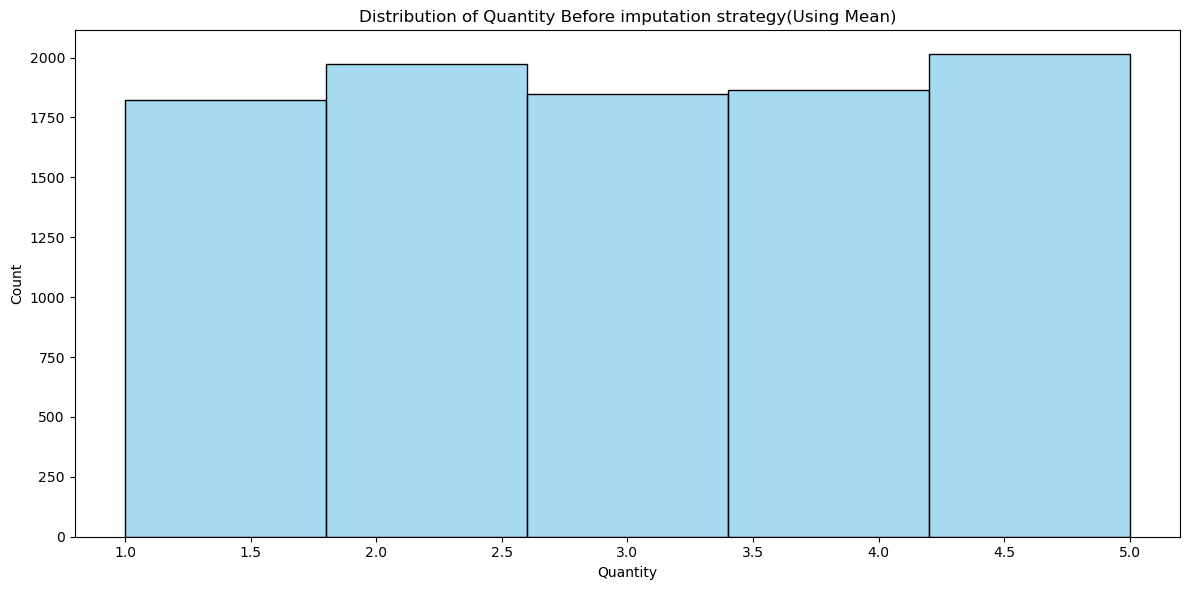

In [14]:
#1, BEFORE the first imputation strategy(Using Mean)
import seaborn as sns
plt.figure(figsize=(12,6))
sns.histplot(df["Quantity"], bins=5,color ="skyblue" )
  
# customizations
# plt.grid(True)
plt.title("Distribution of Quantity Before imputation strategy(Using Mean)")
plt.ylabel("Count")#adds x_label
plt.xlabel("Quantity")#adds y-label
plt.tight_layout()
plt.show()

In [15]:
df["Quantity"].max()

5.0

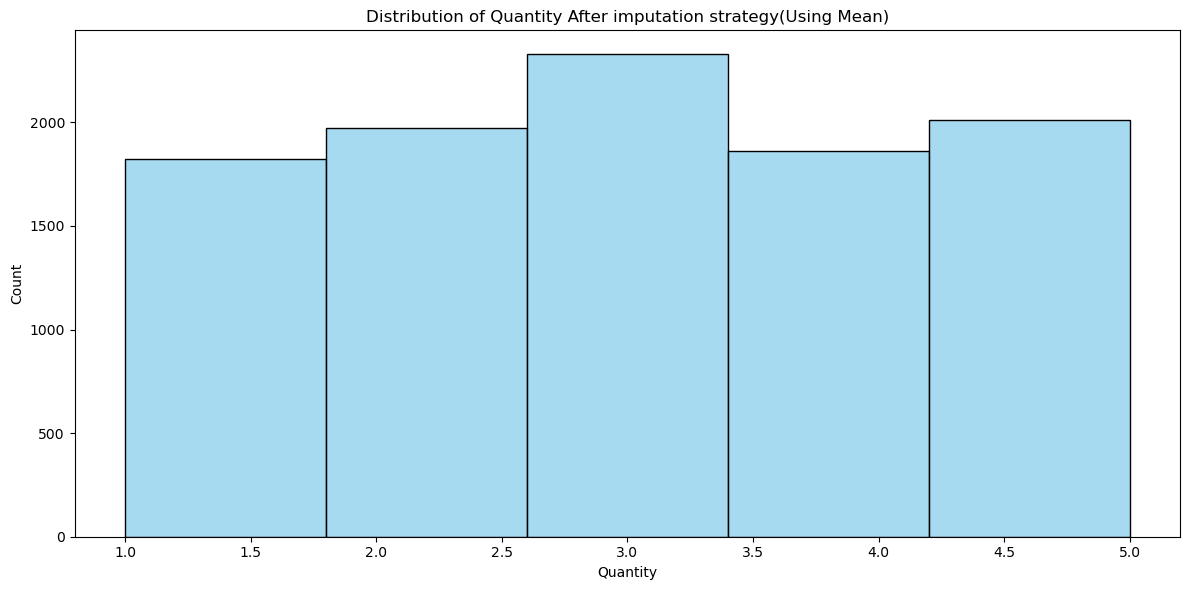

In [16]:
#2, AFTER the second imputation strategy(Using Mean)
import seaborn as sns
plt.figure(figsize=(12,6))
sns.histplot(Mean_df["Quantity"],bins =5,color ="skyblue" )
  
# customizations
# plt.grid(True)
plt.title("Distribution of Quantity After imputation strategy(Using Mean)")
plt.ylabel("Count")#adds x_label
plt.xlabel("Quantity")#adds y-label
plt.tight_layout()
plt.show()

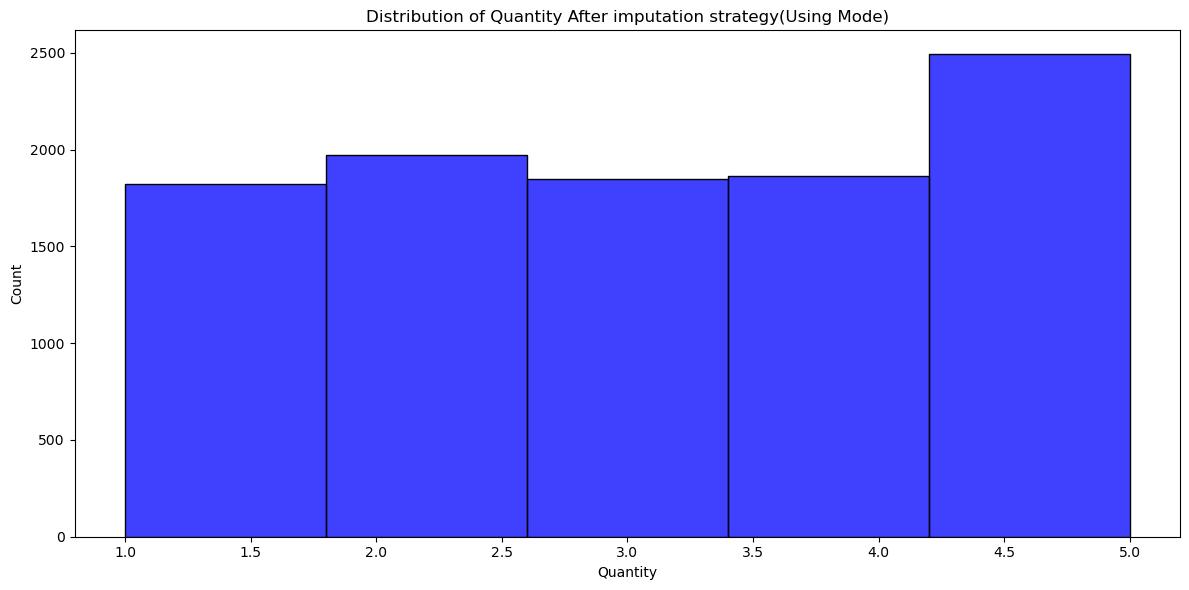

In [17]:
#3, AFTER the second imputation strategy(Using Mode)
import seaborn as sns
plt.figure(figsize=(12,6))
sns.histplot(Mode_df["Quantity"],bins =5,color ="blue" )
  
# customizations
# plt.grid(True)
plt.title("Distribution of Quantity After imputation strategy(Using Mode)")
plt.ylabel("Count")#adds x_label
plt.xlabel("Quantity")#adds y-label
plt.tight_layout()
plt.show()

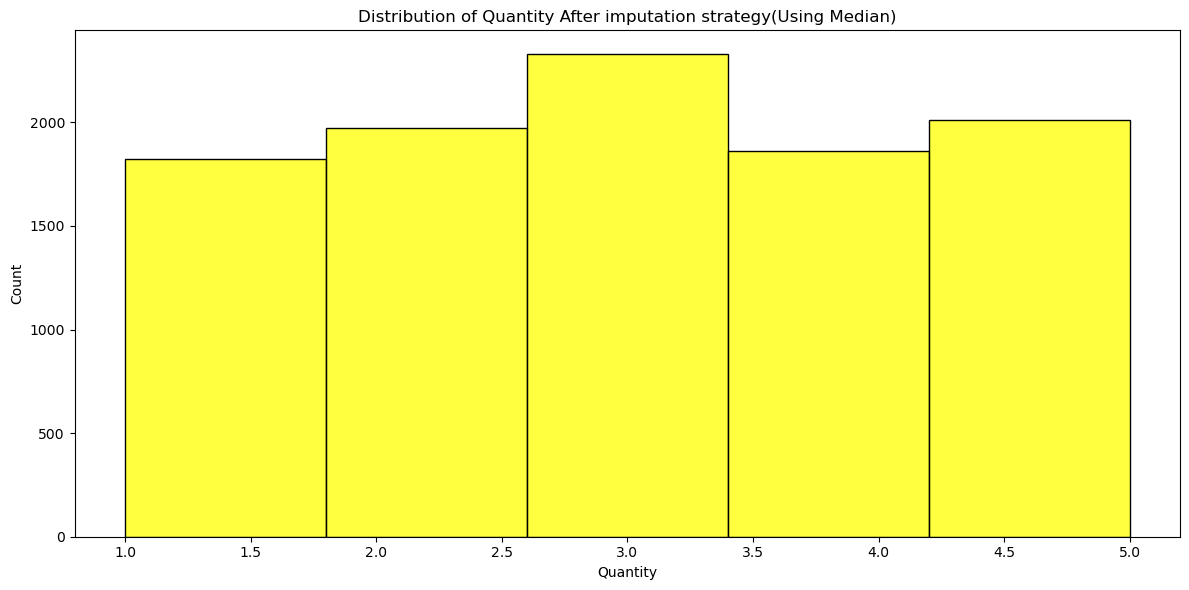

In [18]:
#3, AFTER the third imputation strategy(Using Mode)
import seaborn as sns
plt.figure(figsize=(12,6))
sns.histplot(Median_df["Quantity"],bins =5,color ="yellow" )
  
# customizations
# plt.grid(True)
plt.title("Distribution of Quantity After imputation strategy(Using Median)")
plt.ylabel("Count")#adds x_label
plt.xlabel("Quantity")#adds y-label
plt.tight_layout()
plt.show()

In [19]:
#TASK 25: Duplicate Hunter: Creating  a  DataFrame with intentional duplicates (exact rows and near-duplicates with minor differences).

In [20]:
#i, creating the data frame
students_df = pd.DataFrame({"Name":["rums","david","mary","david","rums","cindy"],"Age":[21,13,18,13,21,20],"Sex":["male","male","Female","male","male","Female"],"City":["USA","New york","Dehli","New york","USA","Tokyo"]})

In [21]:
students_df

,Name,Age,Sex,City
0,rums,21,male,USA
1,david,13,male,New york
2,mary,18,Female,Dehli
3,david,13,male,New york
4,rums,21,male,USA
5,cindy,20,Female,Tokyo


In [22]:
#Write code to: detect exact duplicates,remove them, then detect rows where the combination of 2 key columns is duplicated

#ii,Detecting exact duplicates
students_df.duplicated()

0    False
1    False
2    False
3     True
4     True
5    False
dtype: bool

In [23]:
#iii,removing exact duplicates
students_df.drop_duplicates()

,Name,Age,Sex,City
0,rums,21,male,USA
1,david,13,male,New york
2,mary,18,Female,Dehli
5,cindy,20,Female,Tokyo


In [24]:
#iv, detecting rows where the combination of 2 key columns is duplicated
students_df.duplicated(subset=["Age","Sex"],keep=False)
#keep=False ensures it returns true for every row for which a combination of Age and Sex is thesame

0     True
1     True
2    False
3     True
4     True
5    False
dtype: bool

In [25]:
#In addition to get these rows for which  the combination of 2 key columns is duplicated, we use
duplicated_rows = students_df[students_df.duplicated(subset=["Age","Sex"],keep=False)]
duplicated_rows 

,Name,Age,Sex,City
0,rums,21,male,USA
1,david,13,male,New york
3,david,13,male,New york
4,rums,21,male,USA


In [26]:
# Task 26: Real Dataset Clean:6. Real Dataset Clean: Find a dataset on Kaggle with documented quality issues.Clean it completely: handle all NaN values (documenting each decision), remove 
#duplicates, and produce a "cleaned vs raw" comparison showing row/column counts 
#and null counts before and after. 

In [27]:
#i,Loading the raw dataset
df2 = pd.read_csv("customer_satisfaction_data.csv")

df2.head()

,Customer ID,Product Category,Satisfaction Score,Days for Delivery,Customer Service Interaction,Purchase Amount,Customer Age,Gender
0,CUST0022,Electronics,7.0,8.0,No,89.71,NaN,M
1,NaN,Books,NaN,3.0,Y,178.39,52.0,Female
2,CUST0748,Home Goods,8.0,6.0,no,81.71,33.0,Other
3,CUST0244,Electronics,9.0,7.0,Yes,83.18,46.0,Other
4,CUST0684,Books,NaN,7.0,Yes,68.80,36.0,Male


In [28]:
df2.columns

Index(['Customer ID', 'Product Category', 'Satisfaction Score',
       'Days for Delivery', 'Customer Service Interaction', 'Purchase Amount',
       'Customer Age', 'Gender'],
      dtype='object')

In [29]:
#ii, Record the raw data dimensions
raw_rows, raw_columns = df2.shape

print("RAW DATASET")
print("Rows:", raw_rows)
print("Columns:", raw_columns)

RAW DATASET
Rows: 1050
Columns: 8


In [30]:
#iii checking missing values
print("Missing values before cleaning:")
print(df2.isnull().sum())

Missing values before cleaning:
Customer ID                      52
Product Category                 59
Satisfaction Score               52
Days for Delivery                65
Customer Service Interaction    205
Purchase Amount                  51
Customer Age                     40
Gender                          212
dtype: int64


In [31]:
#iv Handling missing values

#Calculating the median for numerical columns
median_satisfaction = df2["Satisfaction Score"].median()
median_Days_for_Delivery = df2["Days for Delivery"].median()
median_Purchase_Amount = df2["Purchase Amount"].median()
median_Customer_Age = df2["Customer Age"].median()


#calculating mode for categorical columns 
mode_Product_Category = df2["Product Category"].mode()[0]
mode_Customer_Service_Interaction = df2["Customer Service Interaction"].mode()[0]
mode_Gender = df2["Gender"].mode()[0]

#1, Customer ID is an identifier, we can not invent a missing customer ID, so we drop rows where customer ID is missing  
df2 = df2.dropna(subset=["Customer ID"])

#2, Lets Fill numerical columns with median values 
df2["Satisfaction Score"] = df2["Satisfaction Score"].fillna(median_satisfaction)
df2["Days for Delivery"] = df2["Days for Delivery"].fillna(median_Days_for_Delivery)
df2["Purchase Amount"] = df2["Purchase Amount"].fillna(median_Purchase_Amount)
df2["Customer Age"] = df2["Customer Age"].fillna(median_Customer_Age)

#3 lets fill categorical columns with mode 
df2["Product Category"] = df2["Product Category"] .fillna(mode_Product_Category)
df2["Customer Service Interaction"] = df2["Customer Service Interaction"] .fillna(mode_Customer_Service_Interaction)
df2["Gender"] = df2["Gender"].fillna(mode_Gender)

In [32]:
#v verifying that no missing values remain and all has been handled
print("Missing values after cleaning:")
print(df2.isnull().sum())


Missing values after cleaning:
Customer ID                     0
Product Category                0
Satisfaction Score              0
Days for Delivery               0
Customer Service Interaction    0
Purchase Amount                 0
Customer Age                    0
Gender                          0
dtype: int64


In [33]:
#vi Removing duplicates
print("Duplicate rows before cleaning:", df2.duplicated().sum())

df2= df2.drop_duplicates()

print("Duplicate rows after cleaning:", df2.duplicated().sum())

Duplicate rows before cleaning: 47
Duplicate rows after cleaning: 0


In [34]:
#vii Producing the required raw-vs-c;leaned comparison
clean_rows, clean_columns = df2.shape

comparison = pd.DataFrame({
    "Dataset": ["Raw", "Cleaned"],
    "Rows": [raw_rows, clean_rows],
    "Columns": [raw_columns, clean_columns]
})

print(comparison)

   Dataset  Rows  Columns
0      Raw  1050        8
1  Cleaned   951        8


In [35]:
# Task 27 Cleaning Log: Write a function audit_dataframe(df) that prints a full data quality report: shape, dtypes, null counts per column, duplicate count, and the number of unique values per categorical column.

In [36]:
#i, creating the data quality report(we are using the same data set as task 26)
def audit_dataframe(df2):
    print("=" * 60)
    print("DATA QUALITY AUDIT")
    print("=" * 60)

    # Shape
    print("\n1. SHAPE")
    print("Rows:", df2.shape[0])
    print("Columns:", df2.shape[1])

    # Data types
    print("\n2. DATA TYPES")
    print(df2.dtypes)

    # Null counts
    print("\n3. NULL COUNTS")
    print(df2.isnull().sum())

    # Duplicate count
    print("\n4. DUPLICATE COUNT")
    print(df2.duplicated().sum())

    # Unique values for categorical columns
    print("\n5. UNIQUE VALUES IN CATEGORICAL COLUMNS")

    categorical_columns = df2.select_dtypes(
        include=["object", "category"]
    ).columns

    for column in categorical_columns:
        print(f"\n{column}:")
        print("Number of unique values:", df2[column].nunique())
audit_dataframe(df2)        

DATA QUALITY AUDIT

1. SHAPE
Rows: 951
Columns: 8

2. DATA TYPES
Customer ID                      object
Product Category                 object
Satisfaction Score              float64
Days for Delivery               float64
Customer Service Interaction     object
Purchase Amount                 float64
Customer Age                    float64
Gender                           object
dtype: object

3. NULL COUNTS
Customer ID                     0
Product Category                0
Satisfaction Score              0
Days for Delivery               0
Customer Service Interaction    0
Purchase Amount                 0
Customer Age                    0
Gender                          0
dtype: int64

4. DUPLICATE COUNT
0

5. UNIQUE VALUES IN CATEGORICAL COLUMNS

Customer ID:
Number of unique values: 948

Product Category:
Number of unique values: 4

Customer Service Interaction:
Number of unique values: 6

Gender:
Number of unique values: 6
